# CUSTOMER ATTRITION MODELING AND RETENTION STRATEGY

**Prepared by: Shloke Binani** | Academic project

## Summary & Methodology
This analysis uses the public Telco Customer Churn dataset from Kaggle (https://www.kaggle.com/datasets/blastchar/telco-customer-churn), which contains 7,043 customer records and 21 features, to identify what drives customer churn. It tests whether the observed patterns are statistically significant, trains a Random Forest model to predict churn, and sizes two retention scenarios. The findings are also summarized in a Power BI dashboard included in this repository.

In [1]:
#Import libraries & Load Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

# Define the path of the CSV file
file_path = 'Customer-Churn_Telco_Clean.csv'

# Read the data into a pandas DataFrame
df = pd.read_csv(file_path)

# Display the first few rows of the data
print(df.head())
#df.info()
original_data = df.copy()

   Unnamed: 0  customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0           0  7590-VHVEG  Female              0     Yes         No       1   
1           1  5575-GNVDE    Male              0      No         No      34   
2           2  3668-QPYBK    Male              0      No         No       2   
3           3  7795-CFOCW    Male              0      No         No      45   
4           4  9237-HQITU  Female              0      No         No       2   

  PhoneService     MultipleLines InternetService  ... DeviceProtection  \
0           No  No phone service             DSL  ...               No   
1          Yes                No             DSL  ...              Yes   
2          Yes                No             DSL  ...               No   
3           No  No phone service             DSL  ...              Yes   
4          Yes                No     Fiber optic  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0 

In [2]:
#Data Preprocessing
# Drop columns that won't be used for prediction
df = df.drop(['customerID', 'Unnamed: 0'], axis = 1) 

# Categorical columns to label encode.
# NOTE: tenure, MonthlyCharges and TotalCharges are numeric and are deliberately NOT encoded,
# so that MonthlyCharges stays in real dollars (needed for the LTV calculation later).
columns_to_encode = [
                    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
                    'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 
                    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 
                    'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'
]

#Encode categorical variables except the target variable
label_encoders = {}
for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    df[column] = label_encoders[column].fit_transform(df[column])

#Manually encode the target variable 'Churn'
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

# Split data into features and target
X = df.drop('Churn', axis = 1)
y = df['Churn']

#Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size =0.2, random_state= 42)
# random_state = 42 keeps the split and the model reproducible

In [3]:
# Train Random Forest Model
# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators = 100, random_state =42)

#Train the model
_ = rf_model.fit(X_train, y_train)
print(f"Random Forest trained on {len(X_train):,} customers")


Random Forest trained on 5,634 customers


Confusion Matrix: 
[[951  85]
 [203 170]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1036
           1       0.67      0.46      0.54       373

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.70      1409
weighted avg       0.78      0.80      0.78      1409

Baseline accuracy (predict 'no churn' for everyone): 73.5%
ROC AUC: 0.833
Top 10% of risk scores: 76.4% churned (lift 2.89x), captures 28.7% of all churners
Top 20% of risk scores: 65.8% churned (lift 2.49x), captures 49.6% of all churners


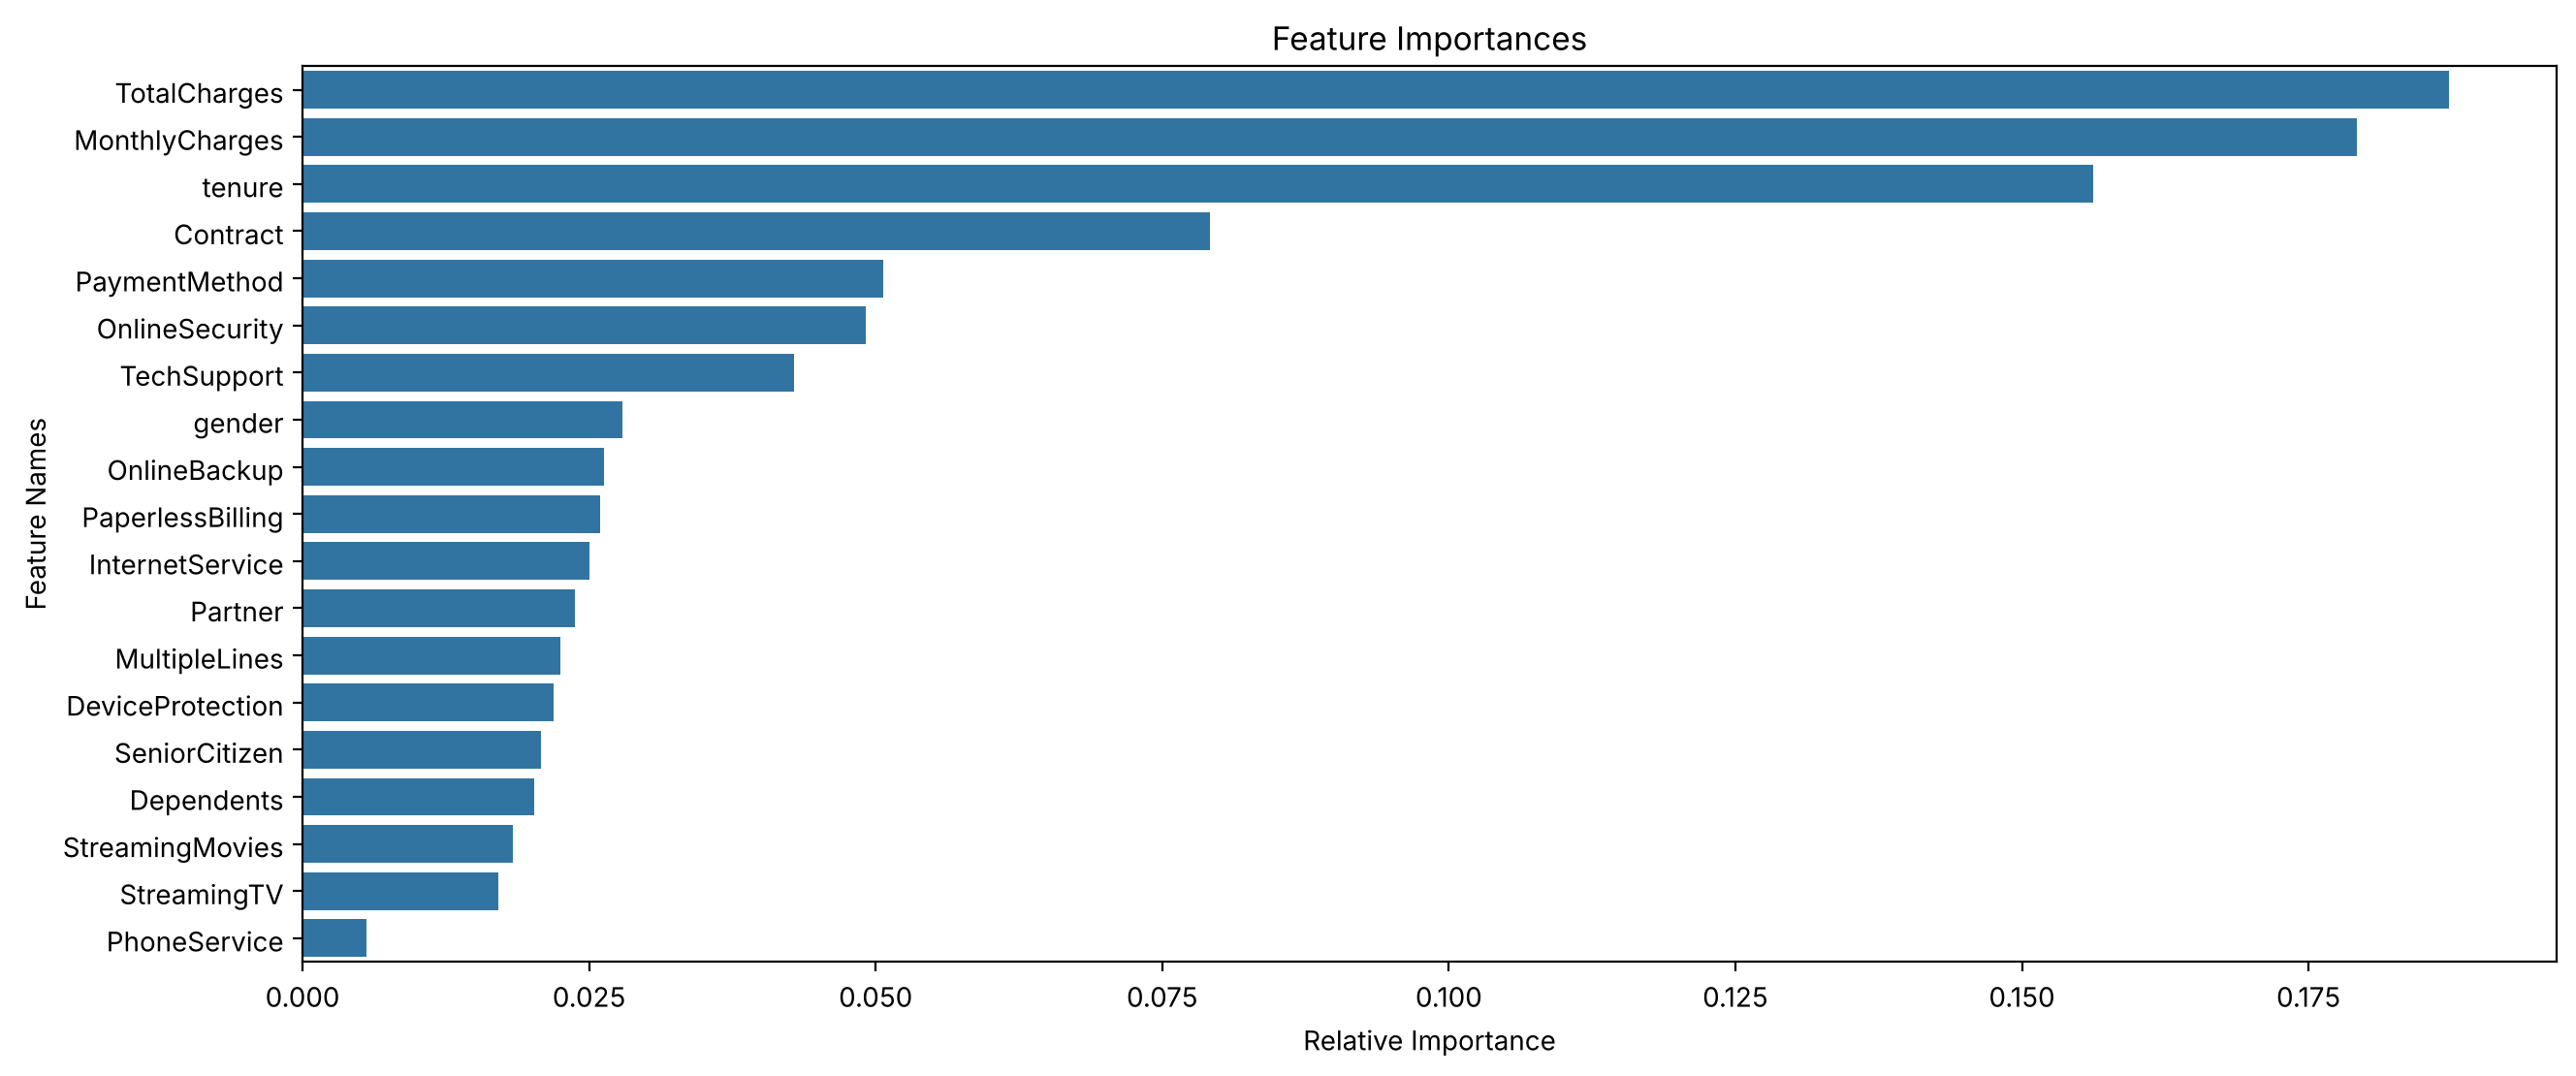

In [4]:
#Evaluate Model
from sklearn.metrics import roc_auc_score

# Make predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

#Evaluate the model
print("Confusion Matrix: ")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Accuracy alone is misleading here: only ~26% of customers churn
print(f"Baseline accuracy (predict 'no churn' for everyone): {1 - y_test.mean():.1%}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob):.3f}")

# How well does the model rank customers by risk?
order = np.argsort(-y_prob)
for pct in (0.10, 0.20):
    k = int(len(order) * pct)
    hit = y_test.values[order[:k]]
    print(f"Top {pct:.0%} of risk scores: {hit.mean():.1%} churned "
          f"(lift {hit.mean() / y_test.mean():.2f}x), captures {hit.sum() / y_test.sum():.1%} of all churners")

#Feature Selection using Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]


#Plot the feature importances
plt.figure(figsize=(15,6))
sns.barplot(x= importances[indices], y = X.columns[indices])
plt.title('Feature Importances')
plt.xlabel('Relative Importance')
plt.ylabel('Feature Names')
plt.show()

## Key Business Questions

The analysis is organized around the following five questions:

<div class ="alert alert-block alert-info">
    <b>1. What is the average tenure of customers who have churned vs. those who haven't?</b>
<br>
    <b>2. What is the churn rate for each InternetService type (DSL, Fiber optic, No service)?</b>
<br>
    <b>3. Do customers with shorter contract types (e.g., Month to Month) churn more frequently than those with long term contracts?</b>
<br>
    <b>4. What is the average LTV (Life Time Value) of churned customers vs. retained customers?</b>
<br>
    <b>5. Among gender, Partner, Dependents, PhoneService, InternetService, Contract, and PaymentMethod, what variable affected the LTV the most?</b>
</div>

## 1. What is the average tenure of customers who have churned vs. those who haven't?

Average Tenure by Churn Status:
Churn
0    37.569965
1    17.979133
Name: tenure, dtype: float64


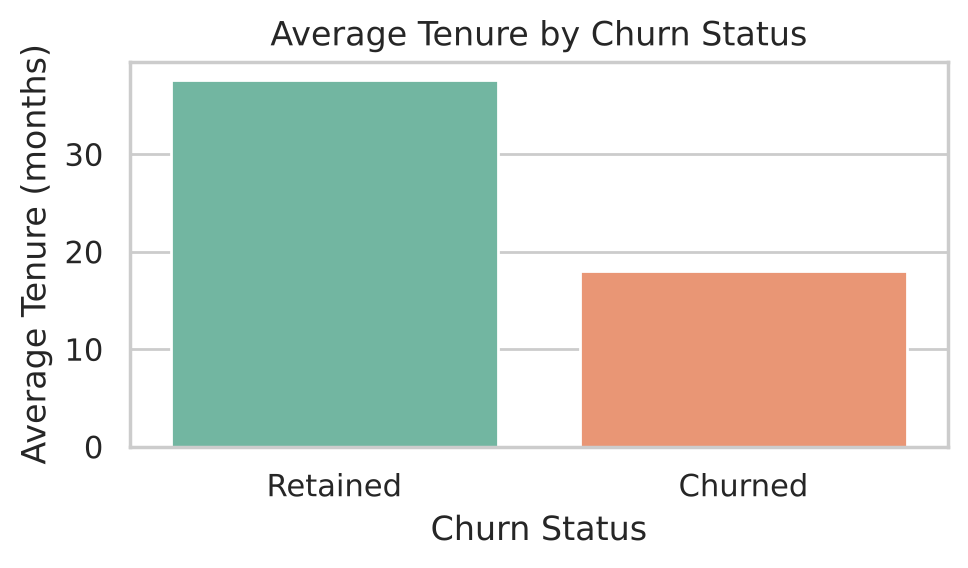

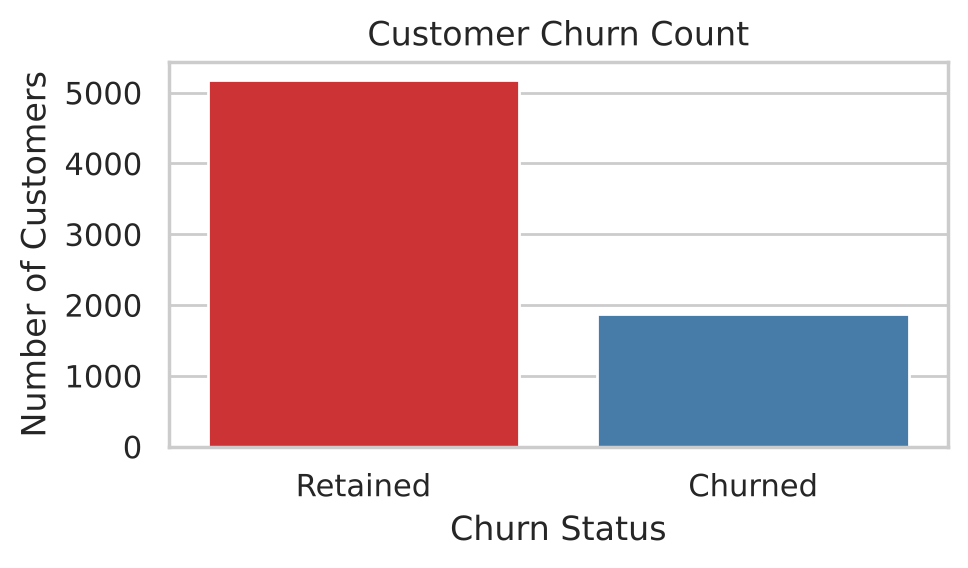

In [5]:
# Readable labels for the charts (0 = retained, 1 = churned)
churn_names = {0: 'Retained', 1: 'Churned'}

# Group by 'Churn' and calculate average tenure
average_tenure = df.groupby('Churn')['tenure'].mean()

print("Average Tenure by Churn Status:")
print(average_tenure)

# Set plot style
sns.set(style="whitegrid")

# Calculate average tenure
avg_tenure = df.groupby('Churn')['tenure'].mean().rename(index=churn_names).reset_index()

# --- Plot 1: Average Tenure by Churn ---
plt.figure(figsize=(5, 3))
sns.barplot(x='Churn', y='tenure', hue='Churn', data=avg_tenure, palette='Set2', legend=False)
plt.title('Average Tenure by Churn Status')
plt.ylabel('Average Tenure (months)')
plt.xlabel('Churn Status')
plt.tight_layout()
plt.show()

# --- Plot 2: Count of Churn vs Non-Churn Customers ---
plt.figure(figsize=(5, 3))
churn_label = df['Churn'].map(churn_names)
sns.countplot(x=churn_label, hue=churn_label, order=['Retained', 'Churned'], palette='Set1', legend=False)
plt.title('Customer Churn Count')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


<div class ="alert alert-block alert-success">
    <b>Insight 1: Tenure & Retention</b>
<br>
* Retained customers (Churn = 0) averaged 37.6 months of tenure.
<br>
* Churned customers (Churn = 1) averaged 18.0 months.
<br>
* 5,174 customers stayed and 1,869 churned (26.5%).
<br><br>
<b>Business Implication:</b> Customers who stay longer are far less likely to churn, so early engagement in the first 18 months matters most for retention.
</div>

## 2. What is the churn rate for each InternetService type (DSL, Fiber optic, No service)?

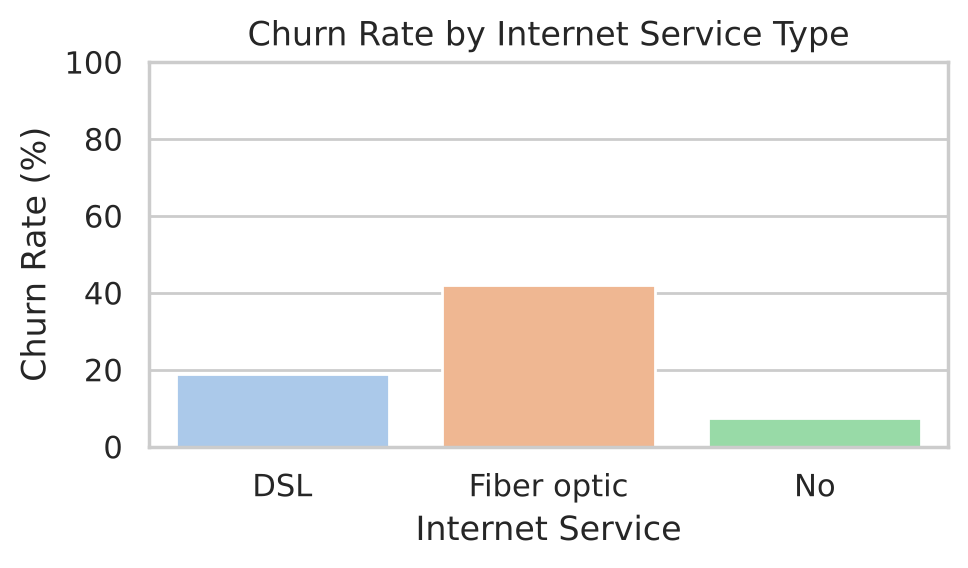

In [6]:
# Group by InternetService and calculate churn rate
churn_rate = df.groupby('InternetService')['Churn'].mean().reset_index()
churn_rate['InternetService'] = label_encoders['InternetService'].inverse_transform(churn_rate['InternetService'])  # back to names
churn_rate['Churn'] *= 100  # convert to percentage
churn_rate.rename(columns={'Churn': 'Churn Rate (%)'}, inplace=True)

# Plot
plt.figure(figsize=(5, 3))
sns.barplot(x='InternetService', y='Churn Rate (%)', hue='InternetService', data=churn_rate, palette='pastel', legend=False)
plt.title('Churn Rate by Internet Service Type')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Internet Service')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

<div class ="alert alert-block alert-success">
    <b>Insight 2: Internet Service Impact</b>
<br>
* Fiber optic customers had the highest churn rate (41.9%).
<br>
* DSL customers churned at 19.0%.
<br>
* Customers with no internet service churned least (7.4%).
<br><br>
<b>Business Implication:</b> Fiber optic customers are the highest risk segment. Pricing and service reliability for this segment should be investigated.
</div>

## 3. Do customers with shorter contract types (e.g., Month-to-Month) churn more frequently than those with long-term contracts?

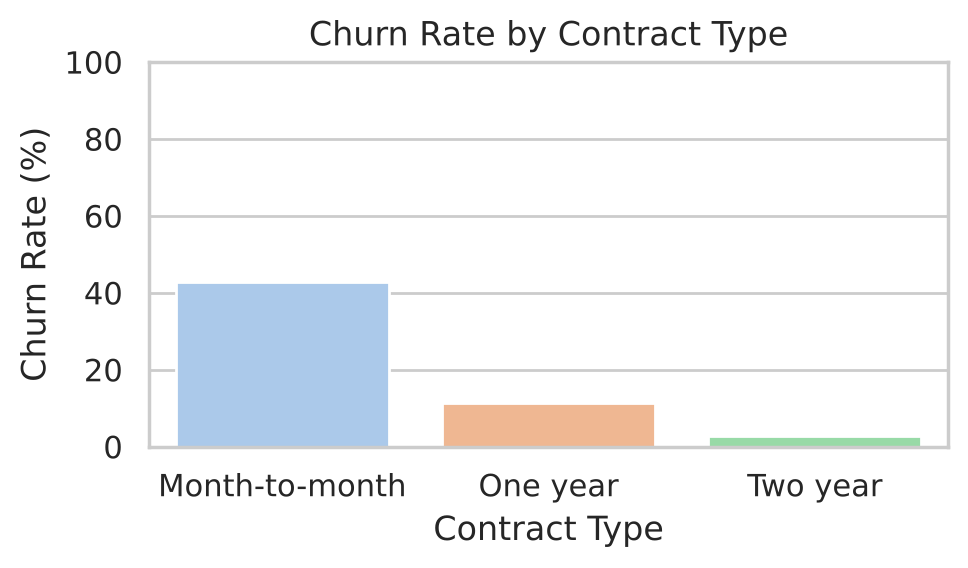

In [7]:
# Calculate churn rate for each contract type
churn_by_contract = df.groupby('Contract')['Churn'].mean().reset_index()
churn_by_contract['Contract'] = label_encoders['Contract'].inverse_transform(churn_by_contract['Contract'])  # back to names
churn_by_contract['Churn Rate (%)'] = churn_by_contract['Churn'] * 100

# Plot
plt.figure(figsize=(5, 3))
sns.barplot(x='Contract', y='Churn Rate (%)', hue='Contract', data=churn_by_contract, palette='pastel', legend=False)
plt.title('Churn Rate by Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Contract Type')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

<div class ="alert alert-block alert-success">
    <b>Insight 3: Contract Length Influence</b>
<br>
* Month-to-month contracts had the highest churn rate (42.7%).
<br>
* One-year contracts had a churn rate of 11.3%.
<br>
* Two-year contracts had the lowest churn rate (2.8%).
<br><br>
<b>Business Implication:</b> Contract length is a primary driver of retention. Promotions that move customers onto longer contracts are worth testing.
</div>

## 4. What is the average LTV (Life Time Value) of churned customers vs. retained customers?

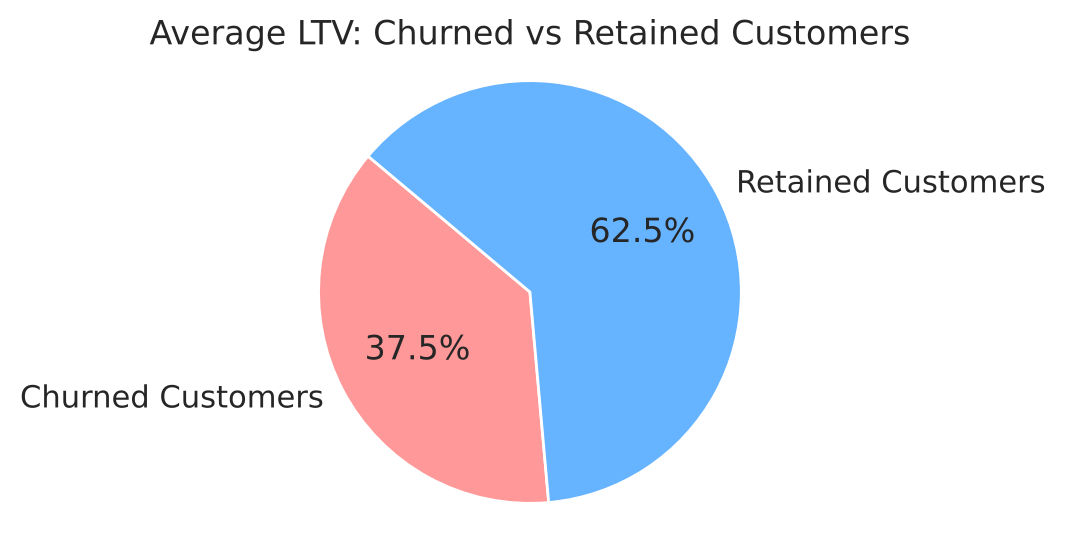

Average LTV - Churned Customers: $1531.61
Average LTV - Retained Customers: $2549.77


In [8]:
# Convert TotalCharges to numeric and drop missing values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna(subset=['MonthlyCharges', 'tenure'])

# Create LTV = MonthlyCharges × Tenure
df['LTV'] = df['MonthlyCharges'] * df['tenure']

# Calculate average LTV for churned and retained
avg_ltv_churned = df[df['Churn'] == 1]['LTV'].mean()
avg_ltv_retained = df[df['Churn'] == 0]['LTV'].mean()

# Prepare data for pie chart
labels = ['Churned Customers', 'Retained Customers']
avg_ltv_values = [avg_ltv_churned, avg_ltv_retained]
colors = ['#ff9999','#66b3ff']

# Create pie chart
plt.figure(figsize=(3, 3))
plt.pie(avg_ltv_values, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors)
plt.title("Average LTV: Churned vs Retained Customers")
plt.axis('equal')  # Equal aspect ratio ensures pie is drawn as a circle.
plt.show()

# Print exact values
print(f"Average LTV - Churned Customers: ${avg_ltv_churned:.2f}")
print(f"Average LTV - Retained Customers: ${avg_ltv_retained:.2f}")

<div class ="alert alert-block alert-success">
    <b>Insight 4: Lifetime Value (LTV) Discrepancy</b>
<br>
LTV is defined here as MonthlyCharges x tenure (in dollars).
<br>
* Average LTV of churned customers: USD 1,531.61.
<br>
* Average LTV of retained customers: USD 2,549.77.
<br><br>
<b>Business Implication:</b> Retained customers generate about 66% more revenue over their lifetime, so identifying high-risk customers early protects the most valuable accounts.
</div>

## 5. Among 'gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', and 'PaymentMethod', what variable affected the LTV the most?

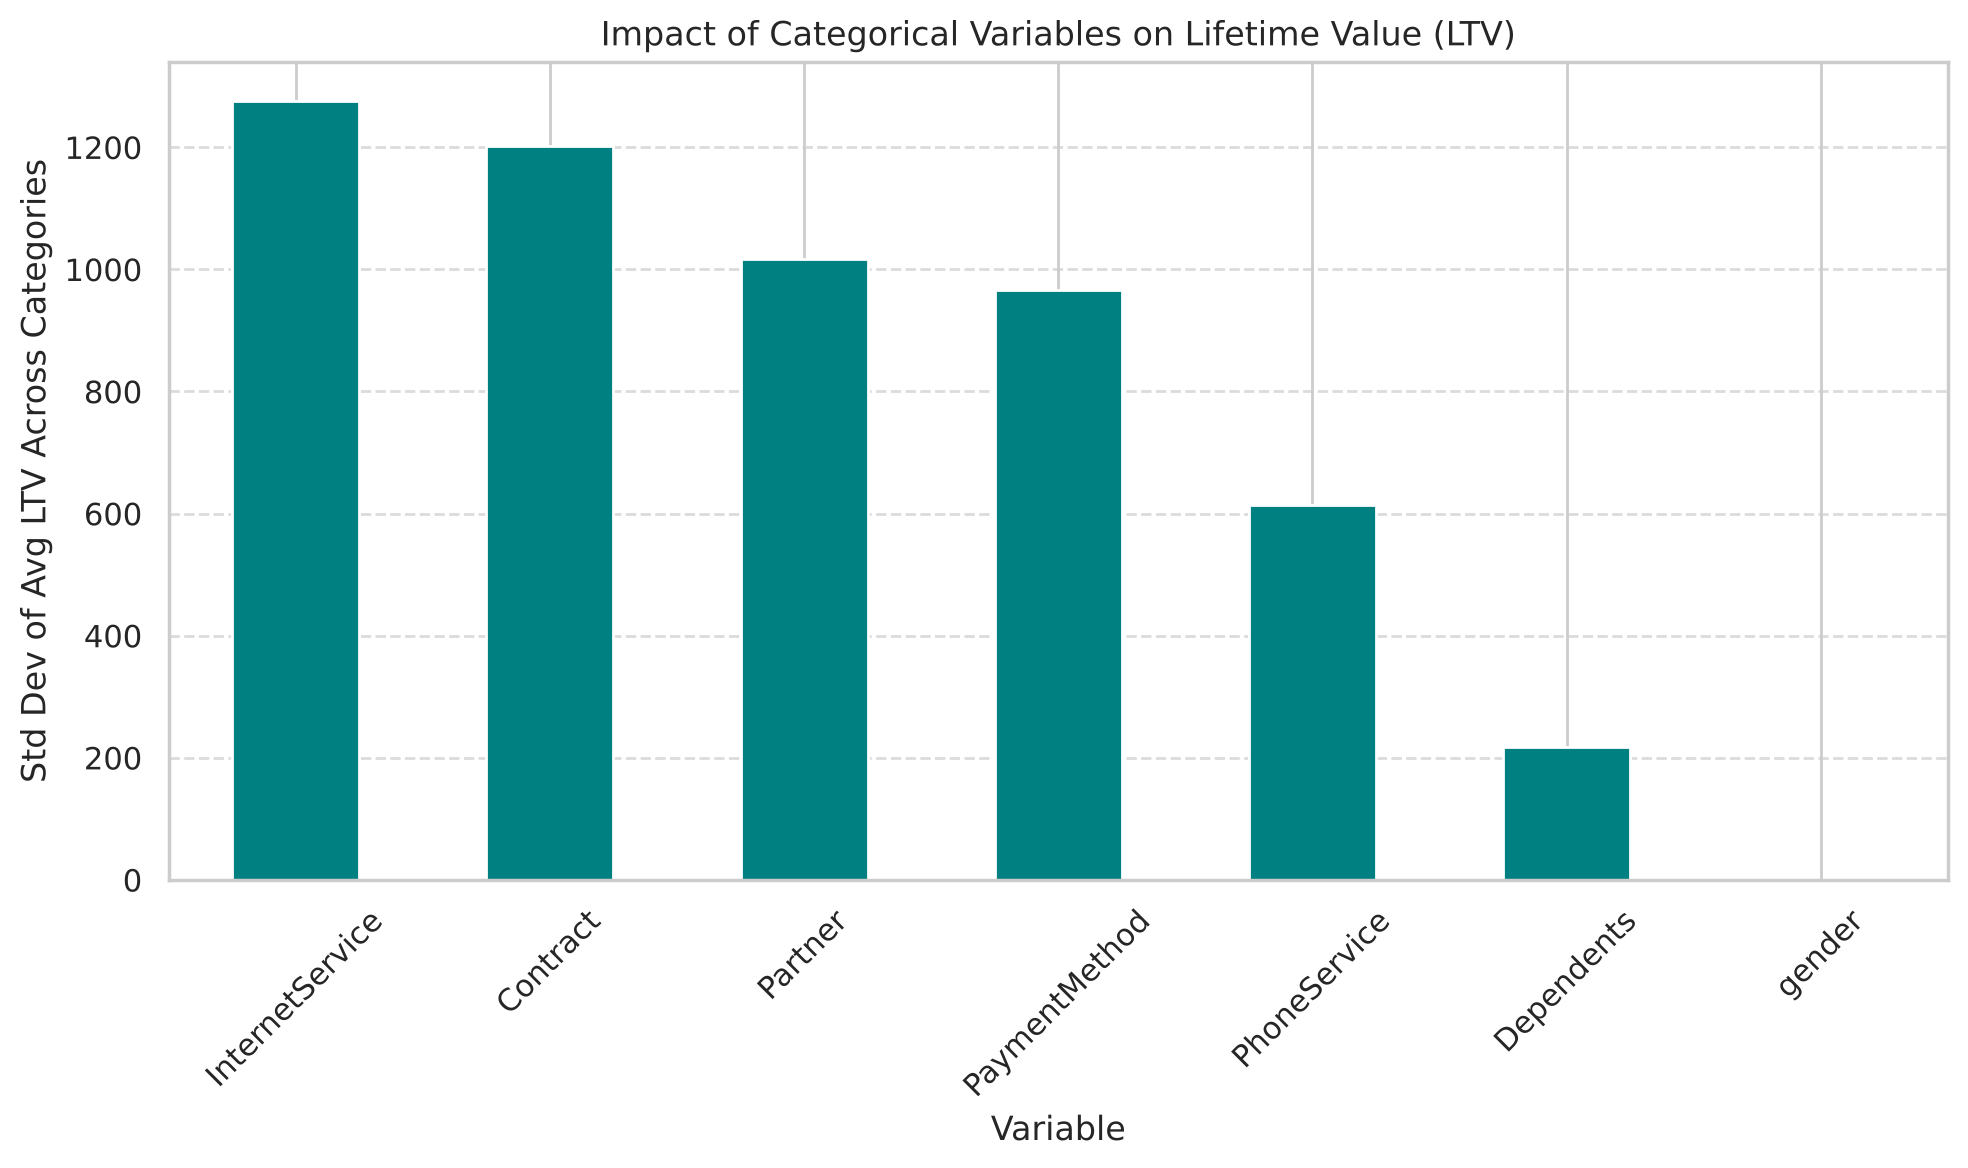

In [9]:

# Create Lifetime Value (LTV)
df['LTV'] = df['MonthlyCharges'] * df['tenure']

# Categorical variables to analyze
categorical_vars = ['gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', 'PaymentMethod']

# Dictionary to store results
ltv_std_by_var = {}

# Loop through each variable and calculate std deviation of avg LTV across its categories
for var in categorical_vars:
    avg_ltv_per_category = df.groupby(var)['LTV'].mean()
    std_of_avg_ltv = avg_ltv_per_category.std()
    ltv_std_by_var[var] = std_of_avg_ltv

# Create DataFrame for plotting
ltv_influence_df = pd.DataFrame.from_dict(ltv_std_by_var, orient='index', columns=['LTV StdDev']).sort_values(by='LTV StdDev', ascending=False)

# Plot bar chart
plt.figure(figsize=(10, 6))
ltv_influence_df['LTV StdDev'].plot(kind='bar', color='teal')
plt.title('Impact of Categorical Variables on Lifetime Value (LTV)')
plt.xlabel('Variable')
plt.ylabel('Std Dev of Avg LTV Across Categories')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


<div class ="alert alert-block alert-success">
    <b>Insight 5: Key Variables Driving LTV</b>
<br>
* InternetService showed the highest variation in LTV across categories, followed by Contract, Partner, PaymentMethod and PhoneService.
<br>
* Dependents and gender had minimal impact on LTV.
<br><br>
<b>Business Implication:</b> Internet service type and contract structure are the strongest levers on customer revenue.
</div>

## 6. Are these differences statistically significant? (Hypothesis testing)

Significance level: alpha = 0.05.

* **Chi-square tests of independence.** H0: churn is independent of the variable. H1: churn depends on the variable. Cramer's V is reported as the effect size.
* **Welch t-tests.** H0: the mean is equal for churned and retained customers. H1: the means differ.

In [10]:
from scipy import stats

raw = original_data  # original (un-encoded) data

rows = []
for col in ['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen', 'gender']:
    table = pd.crosstab(raw[col], raw['Churn'])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append([col, round(chi2, 1), dof, f"{p:.2e}", round(cramers_v, 3),
                 'Reject H0' if p < 0.05 else 'Fail to reject H0'])
print(pd.DataFrame(rows, columns=['Variable', 'Chi2', 'dof', 'p-value', "Cramer's V", 'Decision']).to_string(index=False))

print("\nWelch t-tests (churned vs retained)")
for col in ['tenure', 'MonthlyCharges']:
    a = raw.loc[raw.Churn == 'Yes', col]
    b = raw.loc[raw.Churn == 'No', col]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    print(f"{col}: churned {a.mean():.2f} vs retained {b.mean():.2f}, t = {t:.1f}, p = {p:.2e}")

       Variable   Chi2  dof   p-value  Cramer's V          Decision
       Contract 1184.6    2 5.86e-258       0.410         Reject H0
InternetService  732.3    2 9.57e-160       0.322         Reject H0
  PaymentMethod  648.1    3 3.68e-140       0.303         Reject H0
  SeniorCitizen  159.4    1  1.51e-36       0.150         Reject H0
         gender    0.5    1  4.87e-01       0.008 Fail to reject H0

Welch t-tests (churned vs retained)
tenure: churned 17.98 vs retained 37.57, t = -34.8, p = 1.20e-232


MonthlyCharges: churned 74.44 vs retained 61.27, t = 18.4, p = 8.59e-73


<div class ="alert alert-block alert-success">
    <b>Insight 6: Statistical significance</b>
<br>
* Contract, internet service, payment method and senior citizen status are all significantly associated with churn (p < 0.001). Contract has the largest effect (Cramer's V = 0.41).
<br>
* Gender is not associated with churn (p = 0.49).
<br>
* Churned customers have significantly lower tenure (18.0 vs 37.6 months) and higher monthly charges (USD 74.44 vs USD 61.27), both p < 0.001.
</div>

## 7. Scenario analysis

The scenarios below use stated assumptions. They are observational estimates, not proof of causal effects.

In [11]:
# Scenario 1: move month-to-month customers to one-year contracts
mtm = raw[raw.Contract == 'Month-to-month']
r_mtm = (mtm.Churn == 'Yes').mean()
r_1y = (raw[raw.Contract == 'One year'].Churn == 'Yes').mean()
print(f"Month-to-month customers: {len(mtm):,}, churn {r_mtm:.1%}; one-year churn {r_1y:.1%}")
print("ASSUMPTION: customers who switch then churn like today's one-year customers.")
annual_rev = (mtm.MonthlyCharges * 12).mean()
for share in (0.10, 0.20, 0.30):
    moved = share * len(mtm)
    avoided = moved * (r_mtm - r_1y)
    print(f"  {share:.0%} moved -> {avoided:,.0f} fewer churners "
          f"({avoided / len(raw):.1%} of all customers), ~${avoided * annual_rev:,.0f} annual revenue kept")

# Scenario 2: retention offer to the top 20% of risk scores (test set)
k = int(len(order) * 0.20)
reached = X_test.iloc[order[:k]]
churners_reached = y_test.values[order[:k]].astype(bool)
annual_rev_churners = (reached.MonthlyCharges.values * 12)[churners_reached]
print(f"\nContacting the top 20% of risk scores: {k} customers, {churners_reached.sum()} actual churners reached")
print("ASSUMPTION: the offer saves 10 / 20 / 30% of the churners it reaches.")
for save in (0.10, 0.20, 0.30):
    print(f"  save rate {save:.0%} -> {churners_reached.sum() * save:.0f} customers kept, "
          f"~${annual_rev_churners.sum() * save:,.0f} annual revenue kept")

Month-to-month customers: 3,875, churn 42.7%; one-year churn 11.3%
ASSUMPTION: customers who switch then churn like today's one-year customers.
  10% moved -> 122 fewer churners (1.7% of all customers), ~$97,072 annual revenue kept
  20% moved -> 244 fewer churners (3.5% of all customers), ~$194,145 annual revenue kept
  30% moved -> 365 fewer churners (5.2% of all customers), ~$291,217 annual revenue kept

Contacting the top 20% of risk scores: 281 customers, 185 actual churners reached
ASSUMPTION: the offer saves 10 / 20 / 30% of the churners it reaches.
  save rate 10% -> 18 customers kept, ~$17,468 annual revenue kept
  save rate 20% -> 37 customers kept, ~$34,936 annual revenue kept
  save rate 30% -> 56 customers kept, ~$52,404 annual revenue kept


<div class ="alert alert-block alert-success">
    <b>Insight 7: Scenario results</b>
<br>
* Moving 20% of month-to-month customers to one-year contracts would avoid about 244 churners (3.5% of all customers) and protect roughly USD 194K of annual revenue.
<br>
* Contacting the top 20% of risk scores reaches 185 actual churners; at a 10-30% save rate that keeps 18 to 56 customers (about USD 17K to USD 52K of annual revenue).
</div>

## Limitations
* Single train-test split with no hyperparameter tuning. Churner recall is 46% at the default 0.5 threshold, so the model is better for ranking customers by risk than for yes/no decisions.
* LTV is a simple proxy (monthly charge x tenure), not a forecast of future revenue.
* The scenario estimates assume that customers who switch contracts behave like existing customers on those contracts.
* The dataset is a public benchmark, so no recommendation was tested in practice.